In [86]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [87]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [88]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import pickle
import warnings
warnings.filterwarnings('ignore')

In [89]:
df=pd.read_csv("loan_approved.csv")

In [90]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [91]:
df.isnull().sum()

Loan_ID                    0
Gender                    13
Married                    3
Dependents                15
Education                  0
Self_Employed             32
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                22
Loan_Amount_Term          14
Credit_History            50
Property_Area              0
Loan_Status (Approved)     0
dtype: int64

### imputing the null values:

In [92]:
df['Gender'].value_counts()

Gender
Male      489
Female    112
Name: count, dtype: int64

In [93]:
df.loc[df['Gender'].isnull(),'Gender']="Male"
#we have imputed the null values

In [94]:
df.Gender.isnull().sum()

np.int64(0)

In [95]:
df['Credit_History'].value_counts()

Credit_History
1.0    475
0.0     89
Name: count, dtype: int64

In [96]:
df.loc[df['Credit_History'].isnull(),'Credit_History']=0.0
#we have imputed the null values with 0

In [97]:
df.Credit_History.isnull().sum()

np.int64(0)

In [98]:
df['LoanAmount'].value_counts()

LoanAmount
120.0    20
110.0    17
100.0    15
187.0    12
160.0    12
         ..
292.0     1
142.0     1
350.0     1
496.0     1
253.0     1
Name: count, Length: 203, dtype: int64

In [99]:
df.loc[df['LoanAmount'].isnull(),'LoanAmount']=df['LoanAmount'].median()
#we have imputed the null values with median

In [100]:
df.LoanAmount.isnull().sum()

np.int64(0)

In [101]:
df['Married'].value_counts()

Married
Yes    398
No     213
Name: count, dtype: int64

In [102]:
df.loc[df['Married'].isnull(),'Married']="Yes"
#we have imputed the null values with married

In [103]:
df.Married.isnull().sum()

np.int64(0)

In [104]:
df['Education'].value_counts()

Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64

In [105]:
df.loc[df['Education'].isnull(),'Education']="Graduate"
#we have imputed the null values with graduates

In [106]:
df.Education.isnull().sum()

np.int64(0)

In [107]:
df['Self_Employed'].value_counts()

Self_Employed
No     500
Yes     82
Name: count, dtype: int64

In [108]:
df.loc[df['Self_Employed'].isnull(),'Self_Employed']="No"
#we have imputed the null values with non self employed

In [109]:
df.Self_Employed.isnull().sum()

np.int64(0)

In [110]:
df['Property_Area'].value_counts()

Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64

In [111]:
df.loc[df['Property_Area'].isnull(),'Property_Area']="Semiurban"

In [112]:
df.Property_Area.isnull().sum()

np.int64(0)

In [113]:
df['Dependents'].value_counts()

Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64

In [114]:
df.loc[df['Dependents'].isnull(),'Dependents']='0'

In [115]:
df.Dependents.isnull().sum()

np.int64(0)

In [116]:
df['ApplicantIncome'].value_counts()

ApplicantIncome
2500    9
4583    6
6000    6
2600    6
3750    5
       ..
3232    1
2900    1
4106    1
8072    1
7583    1
Name: count, Length: 505, dtype: int64

In [117]:
df.loc[df['ApplicantIncome'].isnull(),'ApplicantIncome']=df['ApplicantIncome'].mode()

In [118]:
df.ApplicantIncome.isnull().sum()

np.int64(0)

In [119]:
df['CoapplicantIncome'].value_counts()

CoapplicantIncome
0.0       273
2083.0      5
1666.0      5
2500.0      5
5625.0      3
         ... 
2792.0      1
4301.0      1
3800.0      1
1411.0      1
240.0       1
Name: count, Length: 287, dtype: int64

In [120]:
df.loc[df['CoapplicantIncome'].isnull(),'CoapplicantIncome']=df['CoapplicantIncome'].median()

In [121]:
df.CoapplicantIncome.isnull().sum()

np.int64(0)

In [122]:
df['Loan_Amount_Term'].value_counts()

Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64

In [123]:
df.loc[df['Loan_Amount_Term'].isnull(),'Loan_Amount_Term']=df['Loan_Amount_Term'].median()

In [124]:
df.Loan_Amount_Term.isnull().sum()

np.int64(0)

<Axes: xlabel='ApplicantIncome'>

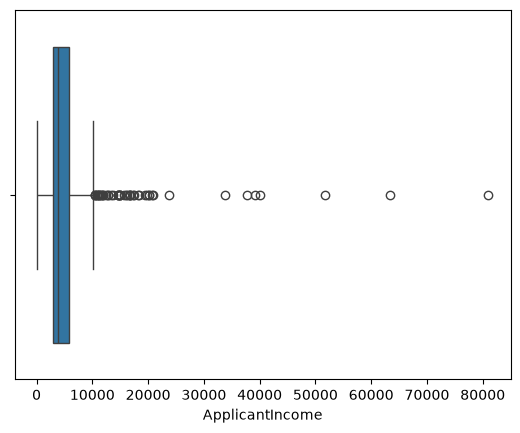

In [125]:
sns.boxplot(x=df.ApplicantIncome,orient='h')

In [126]:
from scipy.stats.mstats import winsorize
trim_percentage = 0.08
df['ApplicantIncome'] = winsorize(df['ApplicantIncome'],limits=trim_percentage)

<Axes: xlabel='ApplicantIncome'>

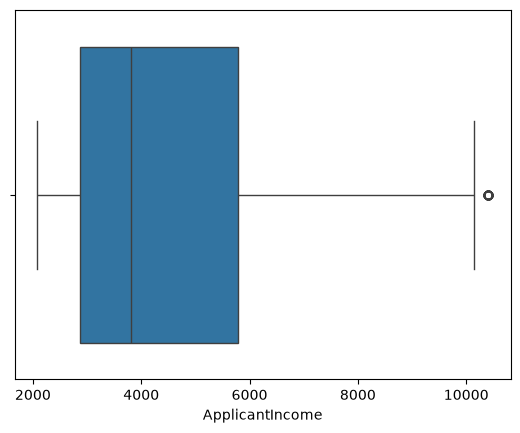

In [127]:
sns.boxplot(x=df.ApplicantIncome,orient='h')

In [128]:
#using interqurtile range method to handle outliers:

In [129]:
#calculate quartile
Q1 = df['LoanAmount'].quantile(0.25)
Q3 = df['LoanAmount'].quantile(0.75)

In [130]:
#calculate IQR
IQR = Q3 - Q1
IQR

np.float64(64.5)

In [131]:
# define upper and lower bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [132]:
print(lower_bound)
print(upper_bound)

3.5
261.5


In [133]:
#remove outliers
df = df[(df['LoanAmount'] >= lower_bound) & (df['LoanAmount'] <= upper_bound)]

<Axes: xlabel='LoanAmount'>

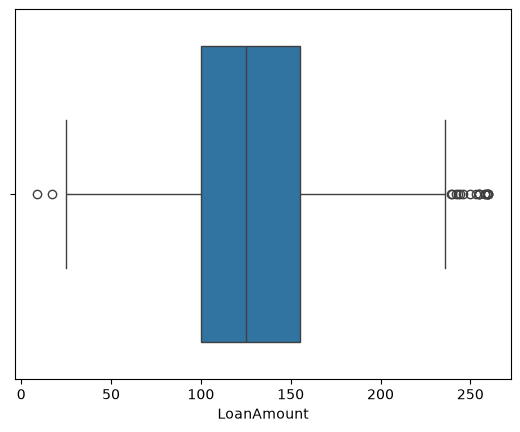

In [134]:
sns.boxplot(x=df.LoanAmount , orient='h')

In [135]:
from scipy.stats.mstats import winsorize
trim_percentage = 0.08
df['LoanAmount'] = winsorize(df['LoanAmount'],limits=trim_percentage)

<Axes: xlabel='LoanAmount'>

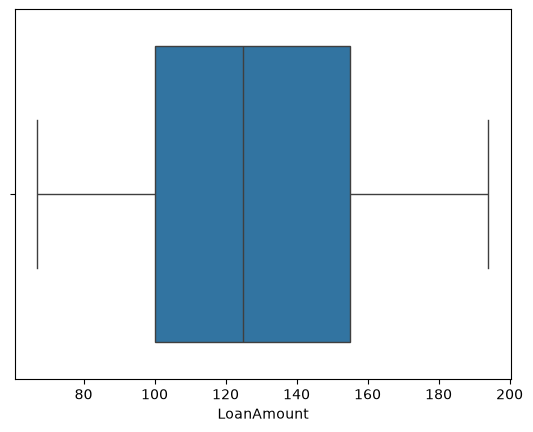

In [136]:
sns.boxplot(x=df.LoanAmount , orient='h')

In [137]:
df_encoding = pd.get_dummies(df, columns=['Married'],prefix='Married')

In [138]:
df_encoding.columns

Index(['Loan_ID', 'Gender', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)', 'Married_No', 'Married_Yes'],
      dtype='str')

In [139]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

df['Married'] = encoder.fit_transform(df['Married'])

print(df[['Married']])

     Married
0          0
1          1
2          1
3          1
4          0
..       ...
609        0
610        1
611        1
612        1
613        0

[573 rows x 1 columns]


In [140]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

df['Loan_Status (Approved)'] = encoder.fit_transform(df['Loan_Status (Approved)'])

print(df[['Loan_Status (Approved)']])

     Loan_Status (Approved)
0                         1
1                         0
2                         1
3                         1
4                         1
..                      ...
609                       1
610                       1
611                       1
612                       1
613                       0

[573 rows x 1 columns]


In [141]:
Education_enc=OrdinalEncoder(categories=[['Graduate', 'Not Graduate']])

In [142]:
df['Education'] = encoder.fit_transform(df[['Education']])

In [143]:
df.Education.value_counts()

Education
0    440
1    133
Name: count, dtype: int64

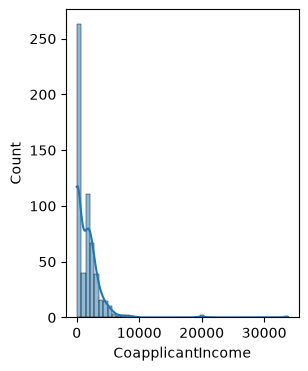

In [144]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['CoapplicantIncome'],kde = True)
plt.show()

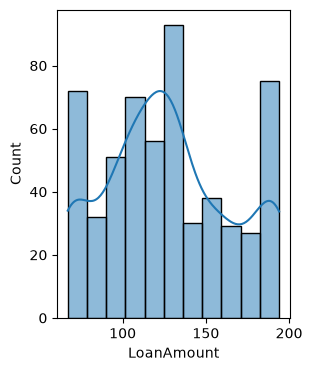

In [145]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['LoanAmount'],kde = True)
plt.show()

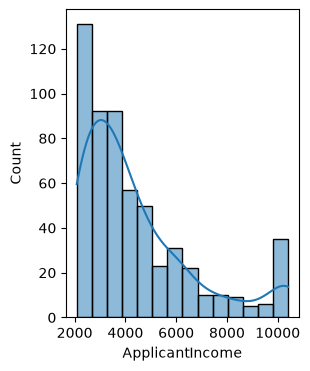

In [146]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['ApplicantIncome'],kde = True)
plt.show()

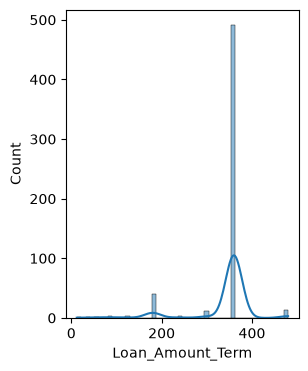

In [147]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['Loan_Amount_Term'],kde = True)
plt.show()

### using log transformation

In [148]:
df['CoapplicantIncome']=np.log(df['CoapplicantIncome'])

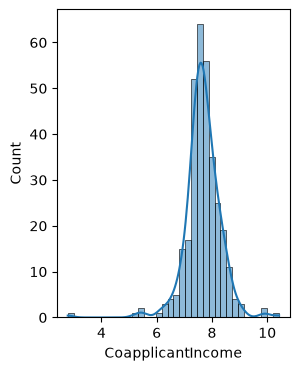

In [149]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['CoapplicantIncome'],kde = True)
plt.show()# Target columns

In [150]:
df['ApplicantIncome_exponential']=df.ApplicantIncome**(1/1.2)

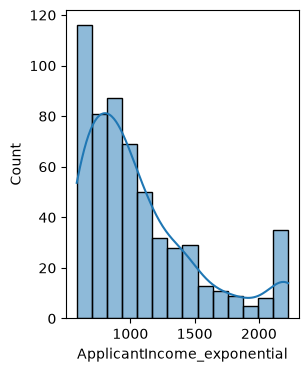

In [151]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['ApplicantIncome_exponential'],kde = True)
plt.show()

In [152]:
df['LoanAmount']=df.LoanAmount**(1/2)

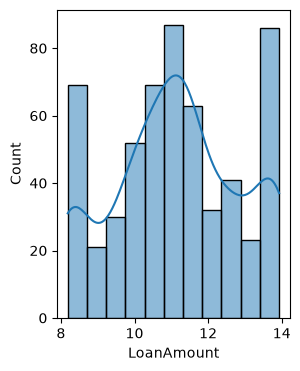

In [153]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['LoanAmount'],kde = True)
plt.show()

In [154]:
from scipy.stats import boxcox
transformed_data,lambda_value = boxcox(df['Loan_Amount_Term'])

In [155]:
print("Lambda value:", lambda_value)

Lambda value: 3.0185540252193874


### Standard scaler

In [156]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)', 'ApplicantIncome_exponential'],
      dtype='str')

In [163]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
ApplicantIncome_scaled = scaler.fit_transform(df[['ApplicantIncome']])

### MinMax Scaler

In [164]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
ApplicantIncome_scaled2 = scaler.fit_transform(df[['ApplicantIncome']])

### RobustScaler

In [165]:
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
ApplicantIncome_scaled3 = scaler.fit_transform(df[['ApplicantIncome']])

In [166]:
## regression == continuous
##classification == Binary and Multiclass classification